## Stochastic Particle Flow Smoother Example using Lorenz 96 model

Created on Wed. September 16 20:01:03 2026

@author: Hao-Lun Yeh

This notebook shows the idea of the Stochastic Particle Flow Smoother (SPFS).

#### The Stochastic Particle Flow Smoother (SPFS)

While the PFF updates the solutions at one time step with current observations in an assimilation window, it can be extended to a smoother that propagates the observation information backward in time, updating solutions at all time steps across the time window.

We derive the SPFS under a strong-constraint perfect model assumption. The method seeks to determine an optimal initial ensemble that minimizes the discrepancy between model predictions and available observations across an assimilation window.

The SPFS iteratively updates the particles at model time zero ($\mathbf{x}_0$) within the time window. After updating, the particles at model time zero are reintegrated over the assimilation window to calculate the new gradient information for the next iteration. This process continues until the particles converge to the stationary solution of the posterior distribution.

Given $L$ sets of measurements $\lbrace\mathbf{y}_k\rbrace^{L}_{k=1}$ distributed over the window, the SPFS update for the $i^{th}$ particle at model time zero at pseudo time $s$ can be written as the PFF/SPFF, in which the gradient of the logarithm of the posterior now becomes

$$
    \nabla_{\mathbf{x}_{s,0}} \log p(\mathbf{x}_{s,0} | \mathbf{y}) = \sum_{k=1}^{L} \left[{\widetilde{\mathbf{H}}_k}^T \mathbf{R}^{-1} (\mathbf{y}_k - \widetilde{H}_k(\mathbf{x}_{s,0})) \right] - \mathbf{B}^{-1} (\mathbf{x_{s,0}} - \mathbf{x_b})
$$

Here, $\widetilde{H}_k(\mathbf{x}_{s,0}) = H_k(M_{0\rightarrow k}(\mathbf{x}_{s,0}))$ represents the predicted measurements at the time of the $k^{th}$ observation set ($t_k$), in which model state at time zero is propagated forward to the model time $t_k$ using the nonlinear model operator $M_{0\rightarrow k}$ and then mapped to observation space using the observation operator $H$. $\widetilde{\mathbf{H}}_k$ is the gradient of $\widetilde{H}_k(\mathbf{x}_{s,0})$ and its transpose ${\widetilde{\mathbf{H}}_k}^T$ can be expressed by the linearized model $\mathbf{M}_{0\rightarrow k}$ and the linearized observation operator $\mathbf{H}_k$:

$$
    {\widetilde{\mathbf{H}}_k}^T = {\mathbf{M}_{0\rightarrow k}}^T{\mathbf{H}_k}^T
$$

In this formulation, the adjoint model ${\mathbf{M}}^T$ are needed.

Note that the SPFS operates similarly to an ensemble of 4D-Vars method, but particles can interact with each other through the kernel matrix during updates. When $N_p=1$, the particle flow reduced to standard variational methods.

Import the libraries we need for the tutorial

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg
from numba import jit

### 1. Set up the Lorenz 96 model

$\frac{dx_{(a)}}{dt} = (x_{(a+1)} - x_{(a-2)})x_{(a-1)} - x_{(a)} + F$  
  
$x_{(a)}$: the a-th component of model state $x$  
  
$F$: the external forcing, set to a common value of 8  

Here, we set the number of state variables $x$ to be 1000 (can be smaller, e.g., 100, for testing with less computational cost).

In [10]:
# Lorenz 96 model parameters
Nx = 1000  # Number of components
F = 8.0 * np.ones(Nx)  # Forcing term

# Function defining the Lorenz 96 model equations
@jit(nopython=True)
def lorenz_96(x, F):
    dxdt = np.zeros_like(x)
    for i in range(Nx):
        dxdt[i] = (x[(i + 1) % Nx] - x[i - 2]) * x[i - 1] - x[i] + F[i]
    return dxdt

# Function defining the adjoint of the Lorenz 96 model equations
@jit(nopython=True)
def adjoint_lorenz96(lambda_vec, x):
    dldt = np.zeros_like(lambda_vec)
    for i in range(Nx):
        # dldt[i] = lambda_vec[(i - 1) % Nx] * (x[(i - 2) % Nx] - x[(i + 1) % Nx]) + lambda_vec[(i + 2) % Nx] * x[(i + 1) % Nx] - lambda_vec[(i - 1) % Nx] * x[(i - 1) % Nx] - lambda_vec[i]
        dldt[i] = - (lambda_vec[(i + 1) % Nx] * (x[(i + 2) % Nx] - x[(i - 1) % Nx]) - lambda_vec[(i + 2) % Nx] * x[(i + 1) % Nx] + lambda_vec[(i - 1) % Nx] * x[(i - 2) % Nx] - lambda_vec[i])
    return dldt

# Fourth-order Runge-Kutta integration
@jit(nopython=True)
def runge_kutta4(x, F, dt):
    k1 = lorenz_96(x, F)
    k2 = lorenz_96(x + 0.5 * dt * k1, F)
    k3 = lorenz_96(x + 0.5 * dt * k2, F)
    k4 = lorenz_96(x + dt * k3, F)

    x_new = x + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return x_new

# Fourth-order Runge-Kutta integration for the adjoint model
# Args:
# lambda_vec: adjoint state vector
# x: state vector
# dt: time step
@jit(nopython=True)
def runge_kutta4_adjoint(lambda_vec, x, dt):
    k1 = adjoint_lorenz96(lambda_vec, x)
    k2 = adjoint_lorenz96(lambda_vec - 0.5 * dt * k1, x)
    k3 = adjoint_lorenz96(lambda_vec - 0.5 * dt * k2, x)
    k4 = adjoint_lorenz96(lambda_vec - dt * k3, x)

    lambda_new = lambda_vec - (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return lambda_new

### 2. Set up the perfect model  experiments
#### 2.1 Nature run (true state)
Integrate the model for 2500 time steps. One model time step is set to be 0.01.

In [3]:
# Time parameters
timesteps = 2500
dt = 0.01

# Initial conditions
np.random.seed(0)
x0 = np.random.rand(Nx)

# Time integration
x_t = np.zeros((Nx, timesteps))
x_t[:, 0] = x0
for t in range(1, timesteps):
    if t == 1:
        for i in range(Nx):
            if np.mod(i+1, 5) == 0:
                F[i] = 9.0
            else:
                F[i] = 8.0
    else:
        F = 8.0 * np.ones(Nx)
    x_t[:, t] = runge_kutta4(x_t[:, t-1], F, dt)

Plot for the true state (e.g. the 0th component and the 72th component)

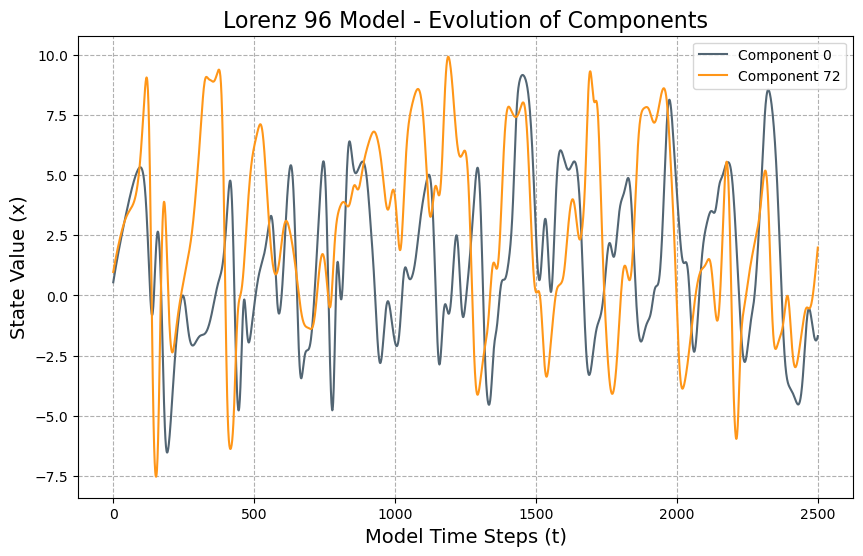

In [4]:
# Plotting

comp_sel1 = 0
comp_sel2 = 72

plt.figure(figsize=(10, 6))
plt.plot(x_t[comp_sel1, :], label=f'Component {comp_sel1}', color='#526573')
plt.plot(x_t[comp_sel2, :], label=f'Component {comp_sel2}', color='#ff9618')
plt.legend()
plt.grid(True, linestyle='--')
plt.title('Lorenz 96 Model - Evolution of Components', fontsize=16)
plt.xlabel('Model Time Steps (t)', fontsize=14)
plt.ylabel('State Value (x)', fontsize=14)
plt.show()

#### 2.2 Generate 20 ensemble members at the 1000th time step
The ensemble 20 ensemble members are generated after the spin-up period (1000 time steps) by perturbing the truth with Gaussian noise $\mathcal{N}(0,2\mathbf{I}_{{n_x}\times{n_x}})$

In [4]:
# Generate 20 ensemble members by adding random perturbations following a normal distribution (N,2)

# Generate ensemble members at model time step 1000
ens_start_time = 1000

# set the ensemble size
ensemble_size = 20

# set the seed
np.random.seed(1)

# mean and standard deviation
mu, sigma = 0, np.sqrt(2)

# initialize an empty list to hold the sets of random numbers
random_numbers_sets = []

# generate 1000 sets of 20 random numbers
for _ in range(Nx):
    random_numbers = np.random.normal(mu, sigma, ensemble_size)
    random_numbers_sets.append(random_numbers)

# now random_numbers_sets is a list of 1000 arrays, each containing 20 random numbers

prior_ens_0 = np.zeros((Nx, ensemble_size))
prior_ens_0 = np.tile(x_t[:, ens_start_time], (ensemble_size,1)).T + np.array(random_numbers_sets) # (N,20)

#### 2.3 Generate observations every 10 model time steps

Select an observation type:  
1. linear: $H(x)=x$  
2. square: $H(x)=x^2$ (nonlinear observation)

In [6]:
obs_type = 'square'   # Please type ['linear', 'square']

Generate observations every 10 model time steps by adding Gaussian noise $\mathcal{N}(0,\mathbf{R})$ to the observation operator working on the truth.  
$\mathbf{R}=\epsilon \mathbf{I}_{{n_y}\times{n_y}}$, where $\epsilon$ is the observational error variance and $n_y$ is the number of observations. The observation consists of $n_y=\frac{1}{4}n_x$ uniformly distributed measurements, sampling every fourth variable in the system ($25\%$ of the system is observed).

In [7]:
# Generate observation by adding random perturbations following a normal distribution (N,obs_eps)

Ny = Nx//4  # Number of observations
assim_period = 10  # Observed every 10 time steps

# Observation error standard deviation
if obs_type == 'linear':
    obs_eps = 0.5
elif obs_type == 'square':
    obs_eps = 1.0
# obs_eps = 1.0

# set the number of observation sets
Number_of_obs_sets = int((timesteps-ens_start_time)/assim_period)

# set the seed
np.random.seed(2)
# mean and standard deviation
mu, sigma = 0, np.sqrt(obs_eps)

# initialize an empty list to hold the sets of random numbers
random_numbers_sets = []

# generate 250 sets of "Number_of_obs_sets" random numbers
for _ in range(Ny):
    random_numbers = np.random.normal(mu, sigma, Number_of_obs_sets)
    random_numbers_sets.append(random_numbers)

# now random_numbers_sets is a list of 250 arrays, each containing "Number_of_obs_sets" random numbers

obs_set = np.zeros((Ny, Number_of_obs_sets))
if obs_type == 'linear':
    obs_set = x_t[::4, ens_start_time::assim_period] + np.array(random_numbers_sets)
elif obs_type == 'square':
    obs_set = np.square(x_t[::4, ens_start_time::assim_period]) + np.array(random_numbers_sets)

Plot for the initial ensemble at the 1000th time step (denoted "t = 0") and all the observations for one of the observed variable, e.g., the 72th component.

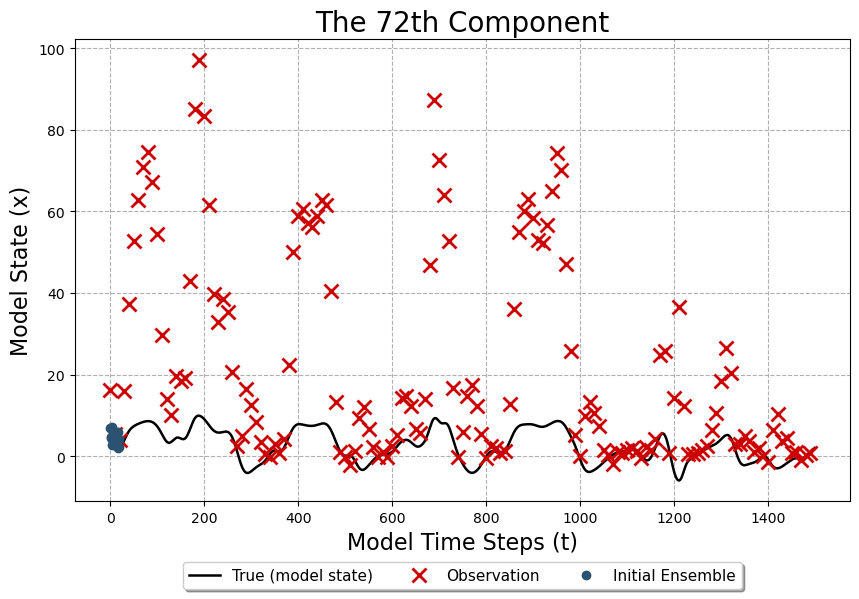

In [8]:
comp_sel = 72

plt.figure(figsize=(10, 6))
plt.plot(x_t[comp_sel, ens_start_time::], label='True (model state)', color='k', linewidth=1.8)
obs_full = np.full((timesteps-ens_start_time),np.nan)
for i in range(Number_of_obs_sets):
    obs_full[i*assim_period] = obs_set[comp_sel//4,i]
plt.plot(obs_full, 'x', label='Observation', color='#CC0000', markeredgewidth=2, markersize=10)
plt.plot(prior_ens_0[comp_sel, :], 'o', label='Initial Ensemble', c='#2b5270')
plt.grid(True, linestyle='--')
# legend = plt.legend(fontsize=12, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.legend(loc='center', fontsize=11, bbox_to_anchor=(0.5, -0.16), ncol=4, fancybox=True, shadow=True)
plt.title(f'The {comp_sel}th Component', fontsize=20)
plt.xlabel('Model Time Steps (t)', fontsize=16)
plt.ylabel('Model State (x)', fontsize=16)
plt.show()

### 3. The Stochastic Particle Flow Smoother (SPFS)
#### 3.1 The SPFS code

In [9]:
def SPFS(prior_ens_fcst, y, obs_eps, ensemble_size, iter_num, alpha, ds, assim_period, integ_time, assim_window):

    # Input to the algorithm
    R_matrix = np.eye(Ny) * obs_eps  #(Ny,Ny)
    R_matrix_inv = np.linalg.inv(R_matrix)

    prior_ens = prior_ens_fcst[:, :, 0]

    # Assume a Gaussian prior in this pseudo code
    prior_mean = np.mean(prior_ens, axis=1)  #(Nx,)

    # generate ensemble perturbation matrix
    ens_perturb = prior_ens - np.tile(prior_mean, (ensemble_size,1)).T  #(Nx,ensemble_size)

    # generate ensemble covariance matrix
    prior_cov = np.dot(ens_perturb, ens_perturb.T) / (ensemble_size - 1)  #(Nx,Nx)

    # localization

    # generate a distance matrix
    r_in = 4    #decorrelation length scale
    i, j = np.meshgrid(np.arange(Nx), np.arange(Nx), indexing='ij')
    dist_matrix = np.exp(-np.square(np.abs(i - j)/r_in))

    prior_cov = prior_cov*dist_matrix  #(Nx,Nx)
    prior_cov_inv = np.linalg.inv(prior_cov)

    L_prior_cov = scipy.linalg.cholesky(prior_cov, lower=True)

    xs_r = np.zeros((Nx, ensemble_size, iter_num+1))
    xs = prior_ens.copy()  #(Nx,ensemble_size)
    xs_r[:,:,0] = xs.copy()

    xs_fcst = np.zeros((Nx, ensemble_size, int(assim_window/assim_period)+1))
    xs_fcst = prior_ens_fcst.copy()

    xs_fcst_r = np.zeros((Nx, ensemble_size, assim_window+1))
    xs_fcst_r[:,:,0] = xs_fcst[:,:,0].copy()
    for t_sm in range(1, assim_window+1):
        for i in range(ensemble_size):
            xs_fcst_r[:, i, t_sm] = runge_kutta4(xs_fcst_r[:, i, t_sm-1], F, dt)

    # iter_norm_less = 0
    iter_norm_large = 0
    norm_2 = np.zeros((iter_num+1))
    # norm_2[0] = 10e8
    s = 0
    # if s < iter_num:
    for iter in range(4000):
        gradient_log_post = np.zeros((Nx, ensemble_size))
        for i in range(ensemble_size):
            # modeled observation
            if obs_type == 'linear':
                yb = xs_fcst[::4, i, :]
                H = np.zeros((Ny, Nx))
                # linearized observation operator
                for j in range(Ny):
                    H[j, 4*j] = 1
            elif obs_type == 'square':
                yb = np.square(xs_fcst[::4, i, :])
                H = np.zeros((Ny, Nx))

            glp_fcst = np.zeros(Nx)

            for t_fcst in range(1, int(assim_window/assim_period)+1):
                if obs_type == 'square':
                    # linearized observation operator
                    for j in range(Ny):
                        H[j, 4*j] = 2*xs_fcst[::4, i, t_fcst][j]
                glp_fcst = np.dot(np.dot(H.T, R_matrix_inv), (y[:, t_fcst-1] - yb[:, t_fcst])) #(Nx,)
                for t_sm in range(assim_period*t_fcst, 0, -1):
                    glp_fcst = runge_kutta4_adjoint(glp_fcst, xs_fcst_r[:, i, t_sm-1], dt)
                gradient_log_post[:, i] += glp_fcst

            # gradient of log posterior
            gradient_log_post[:, i] = gradient_log_post[:, i] - np.dot(prior_cov_inv, (xs[:, i]-prior_mean)) #(Nx,)

        I = np.zeros((Nx, ensemble_size))

        K = np.zeros((ensemble_size, ensemble_size))
        A = (1.0/alpha)*prior_cov_inv
        A_tran = A.T
        for i in range(ensemble_size):
            for j in range(ensemble_size):
                diff_xs = xs[:, i]-xs[:, j]
                N_diff_xs = np.dot(A,diff_xs)
                K[i,j] = np.exp(-0.5*np.dot(diff_xs.T, N_diff_xs))
                dK = np.dot(A_tran, diff_xs)*K[i,j]
                I[:, i] = I[:, i] + (K[i,j]*gradient_log_post[:, j]+dK)/ensemble_size

        # Calculate the stochastic part

        # Generate Gaussian random numbers with mean 0 and variance 1
        # set the seed
        # np.random.seed(4)
        np.random.seed(4+s+iter_num*((integ_time-assim_period)//assim_period-1))
        random_numbers_stochastic = np.random.normal(0, 1, Nx*ensemble_size)

        # Calculate the lower triangular Cholesky decomposition of K matrix
        LK = scipy.linalg.cholesky(K/ensemble_size, lower=True)

        # Efficient calculation of noise, replacing the L_full approach",
        R_Nx_ens = random_numbers_stochastic.reshape(Nx, ensemble_size)
        noise = compute_noise_fast(L_prior_cov, R_Nx_ens, LK.T, np.sqrt(2))

        # print(I.shape)

        norm_2[s] = np.linalg.norm(I)

        # if norm_2[s] < stop_cri_percentage * norm_2[0]:
        #     print('The PFF has been terminated after ', s, ' iterations')
        #     break

        fs = np.dot(prior_cov, I)
        # print(fs)
        print(norm_2[s], norm_2[s-1])

        # Apply the adaptive step size (learning rate)

        if s == 0:
            # xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs
            xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs + np.sqrt(ds)*noise
            s = s+1
            iter_norm_large += 1
            xs = xs_r[:,:,s].copy()
        elif s >= 1 and norm_2[s] > 1.02*norm_2[s-1]:
            ds = ds/1.5
            s = s-1
            xs = xs_r[:,:,s].copy()
            iter_norm_large = 0
            # print('[Note] The eps has been changed to ', ds, '... Redo the PFF based on this eps')
        elif iter_norm_large >= 7 and norm_2[s] <= 1.02*norm_2[s-1]:
            ds = ds*1.5
            # xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs
            xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs + np.sqrt(ds)*noise
            s = s+1
            iter_norm_large = 0
            xs = xs_r[:,:,s].copy()
        else:
            # xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs
            xs_r[:,:,s+1] = xs_r[:,:,s] + ds*fs + np.sqrt(ds)*noise
            s = s+1
            iter_norm_large += 1
            xs = xs_r[:,:,s].copy()

        # print('iter = ', iter)
        # xs_r[:,:,iter+1] = xs.copy()
        print('iter = ', s)
        # print('ds = ', ds)

        print(np.max(np.abs(xs)))
        if s >= iter_num:
            print('The SPFS has been terminated after ', s, ' iterations')
            break

        xs_fcst[:,:,0] = xs.copy()
        xs_fcst_r = np.zeros((Nx, ensemble_size, assim_window+1))
        xs_fcst_r[:,:,0] = xs_fcst[:,:,0].copy()

        for t_sm in range(1, assim_window+1):
            for i in range(ensemble_size):
                xs_fcst_r[:, i, t_sm] = runge_kutta4(xs_fcst_r[:, i, t_sm-1], F, dt)
            if np.mod(t_sm, assim_period) == 0:
                xs_fcst[:,:,int(t_sm/assim_period)] = xs_fcst_r[:,:,t_sm]

    return xs , xs_r

@jit(nopython=True)
def compute_noise_fast(L_prior_cov, random_numbers, LK_T, sqrt_2):
    """Fast noise computation using Numba JIT"""
    temp = np.dot(L_prior_cov, random_numbers)
    return sqrt_2 * np.dot(temp, LK_T)

#### 3.2 Running the sequential DA experiment with SPFS (Observations are collected every 10 steps, and the assimilation window is 20 time-steps).
1. Set the number of iterations
2. Choose a fixed or an adaptive kernel width

In [ ]:
iter_num = 1000     #number of iterations (150 for linear, 1000 for square)
Assim_method = 'SPFS'
kernel_width_type = 'adaptive'  # Please type ['fixed', 'adaptive']

Run the model

In [ ]:
# Fixed parameters for model and (S)PFS
integration_time_step = 500   # total number of time steps for sequential Data Assimilation (maximum: 1500)
assim_window = 20

F = 8.0 * np.ones(Nx)
alpha_0 = Nx    # the base width of the kernel

if obs_type == 'linear':
    ds = 0.05           # step size
elif obs_type == 'square':
    ds = 0.0001

# Number of assimilation cycles
Number_of_smoother_cycles = int(integration_time_step/assim_window)

# Initial conditions
prior_ens_PFF = np.zeros((Nx, ensemble_size, int(integration_time_step/assim_period)+1))
posterior_ens_PFF = np.zeros((Nx, ensemble_size, int(integration_time_step/assim_period)+1))
x_PFF = np.zeros((Nx, ensemble_size, integration_time_step+1))

posterior_ens_PFF[:,:,0] = prior_ens_0.copy()  #(Nx,ensemble_size)
x_PFF[:,:,0] = prior_ens_0.copy()  #(Nx,ensemble_size)

# For smoother
prior_ens_PFF[:,:,0] = prior_ens_0.copy()
prior_x_PFS = np.zeros((Nx, ensemble_size, integration_time_step+1))
posterior_x_PFS = np.zeros((Nx, ensemble_size, integration_time_step+1))

prior_x_PFS[:,:,0] = prior_ens_0.copy()
posterior_x_PFS[:,:,0] = prior_ens_0.copy()
sm_time_idx = 0
sm_cycle_idx = 0

# Set the kernel width and keep a record of the width used at each assimilation cycle
alpha = alpha_0
alpha_list = np.zeros((Number_of_smoother_cycles+1))
alpha_list[0] = alpha_0
print("The", kernel_width_type, "kernel width is used, and the base kernel width is", alpha_0)

# Sequential DA for (S)PFS with 20 time-steps assimilation window
for t in range(1, integration_time_step+1):
# for t in range(1, integration_time_step):

    # Model integration
    for i in range(ensemble_size):
        prior_x_PFS[:, i, t] = runge_kutta4(prior_x_PFS[:, i, t-1], F, dt)

    sm_time_idx = sm_time_idx + 1

    if np.mod(t, assim_period) == 0:
        prior_ens_PFF[:, :, int(t/assim_period)] = prior_x_PFS[:, :, t]

    if np.mod(sm_time_idx, assim_window) == 0:
        # print("Implement PFF at time step ", t, " ...")
        print(f"Implement {Assim_method} at time step ", t, " ...")
        sm_cycle_idx = sm_cycle_idx + 1

        # set the kernel width for this assimilation cycle
        if kernel_width_type == 'fixed':
            alpha = alpha_0
        elif kernel_width_type == 'adaptive':
            # adjust the base kernel width with a factor rho diagnosed from the prior ensemble at
            # the beginning of the assimilation window (the ensemble that the SPFS updates)
            prior_ens_abs = np.abs(prior_ens_PFF[:, :, int((t-assim_window)/assim_period)])  #(Nx,ensemble_size)
            rho = np.square(np.std(prior_ens_abs, axis=1)/np.std(prior_ens_PFF[:, :, int((t-assim_window)/assim_period)], axis=1))  #(Nx,)
            alpha = alpha_0*np.mean(rho)
            print("The kernel width is ", alpha, " at time step ", t, " ...", "The mean of rho is ", np.mean(rho))
        alpha_list[sm_cycle_idx] = alpha

        # run the PFF algorithm
        [posterior_ens_PFF[:,:,int((t-assim_window)/assim_period)], xs_r] = SPFS(prior_ens_PFF[:, :, int((t-assim_window)/assim_period):int(t/assim_period)+1], obs_set[:, int((t-assim_window)/assim_period)+1:int(t/assim_period)+1], obs_eps, ensemble_size, iter_num, alpha, ds, assim_period, t, assim_window)

        # update the model state by posterior ensemble
        posterior_x_PFS[:, :, t-assim_window] = posterior_ens_PFF[:,:,int((t-assim_window)/assim_period)]

        # propagate the posterior ensemble to the next assimilation time step
        for t_sm in range(t-assim_window+1, t+1):
            for i in range(ensemble_size):
                posterior_x_PFS[:, i, t_sm] = runge_kutta4(posterior_x_PFS[:, i, t_sm-1], F, dt)
            if np.mod(t_sm, assim_period) == 0 and t_sm < t:
                # print(t_sm)
                posterior_ens_PFF[:, :, int(t_sm/assim_period)] = posterior_x_PFS[:, :, t_sm]
            if t_sm == t:
                prior_x_PFS[:,:,t_sm] = posterior_x_PFS[:,:,t_sm].copy()
                prior_ens_PFF[:, :, int(t_sm/assim_period)] = posterior_x_PFS[:,:,t_sm].copy()
                sm_time_idx = 0

        # save the ensemble trajectory during the first assimilation period
        # if t == assim_window*1:
        #     xs_r1 = xs_r.copy()

### 4. Let's check the results

#### 4.1 Evolution of the ensemble members

Here, we run the experiment without DA (NoDA) and compare it with the SPFS

In [7]:
# NoDA

# Initial conditions
x_PFF_NoDA = np.zeros((Nx, ensemble_size, integration_time_step+1))
x_PFF_NoDA[:,:,0] = prior_ens_0.copy()  #(Nx,ensemble_size)

# Time integration
for t in range(1, integration_time_step):
    for i in range(ensemble_size):
        x_PFF_NoDA[:, i, t] = runge_kutta4(x_PFF_NoDA[:, i, t-1], F, dt)

Evolution of NoDA ensemble

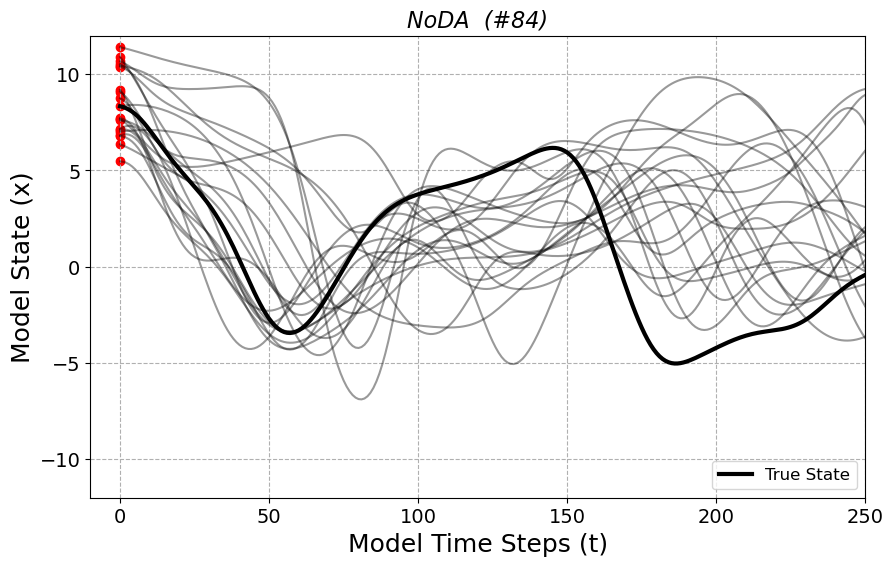

In [9]:
plt.figure(figsize=(10, 6))  # Set the figure size to 10 inches wide and 6 inches tall
comp_sel = 84

plt.plot(x_t[comp_sel, ens_start_time::], 'k', label='True State', linewidth=3)
for i in range(ensemble_size):
    plt.plot(x_PFF_NoDA[comp_sel, i, 0:integration_time_step+1], 'k', alpha=0.4, linewidth=1.5)
# plt.scatter(0*np.ones(ensemble_size), x_PFF[comp_sel, :, 0], c='r')
plt.scatter(0*np.ones(ensemble_size), prior_ens_0[comp_sel], c='r')


plt.xlim(-10, 250)
# plt.xlim(250, 500)
# plt.xlim(-10, 500)
plt.ylim(-12, 12)
plt.title(f'NoDA  (#{comp_sel})', fontsize=16, style='italic')
plt.xlabel('Model Time Steps (t)', fontsize=18)
plt.ylabel('Model State (x)', fontsize=18)
plt.tick_params(labelsize=14)
plt.grid(True, linestyle='--')
legend = plt.legend(fontsize=12, loc='lower right')
plt.show()

Ensemble evolution of SPFS

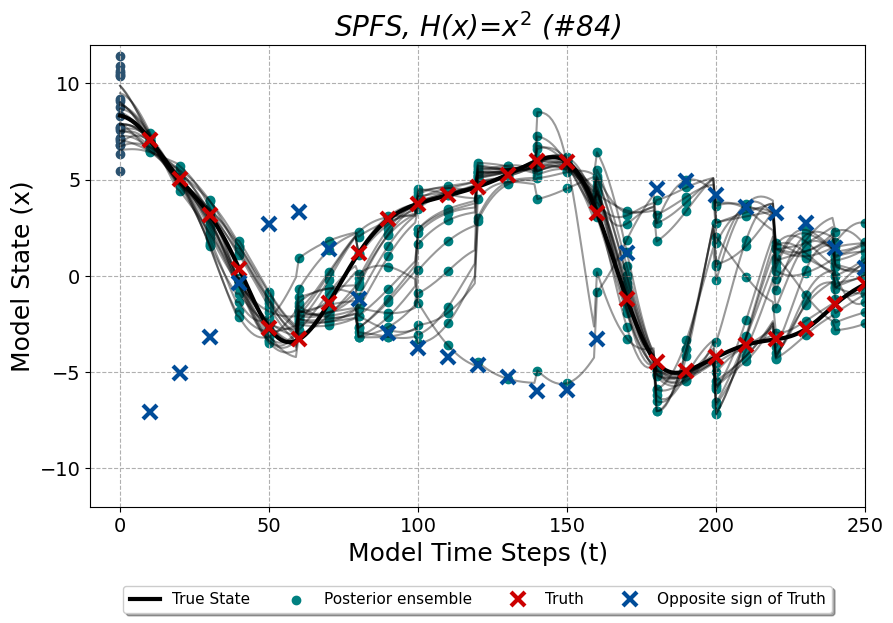

In [83]:
plt.figure(figsize=(10, 6))
comp_sel = 84

plt.plot(x_t[comp_sel, ens_start_time::], 'k', label='True State', linewidth=3)
for i in range(ensemble_size):
    # plt.plot(x_PFF[comp_sel, i, 0:integration_time_step+1], 'k', alpha=0.4, linewidth=1.5)
    plt.plot(posterior_x_PFS[comp_sel, i, 0:integration_time_step+1], 'k', alpha=0.4, linewidth=1.5)
plt.scatter(0*np.ones(ensemble_size), x_PFF[comp_sel, :, 0], c='#2b5270')

for i in range(1,int(integration_time_step//assim_period)+1):
    plt.scatter(i*assim_period*np.ones(ensemble_size), posterior_ens_PFF[comp_sel, :, int(i*assim_period/assim_period)], c='#008080',\
            label='Posterior ensemble' if i == 1 else "")
    if obs_type == 'linear':
        plt.plot(i*assim_period, obs_set[comp_sel//4, i*assim_period//assim_period], 'x', markeredgewidth=3, markersize=10, color='#CC0000',\
        label='Observation' if i == 1 else "")
        plt.title(f'{Assim_method}, H(x)=$x$ (#{comp_sel})', fontsize=20, style='italic')
    elif obs_type == 'square':
        plt.plot(i*assim_period, x_t[comp_sel, ens_start_time+i*assim_period], 'x', markeredgewidth=3, markersize=10, color='#CC0000', label='Truth' if i == 1 else "")
        plt.plot(i*assim_period, -x_t[comp_sel, ens_start_time+i*assim_period], 'x', markeredgewidth=3, markersize=10, color='#004C99', label='Opposite sign of Truth' if i == 1 else "")
        plt.title(f'{Assim_method}, H(x)=$x^2$ (#{comp_sel})', fontsize=20, style='italic')

plt.xlim(-10, 250)
# plt.xlim(250, 500)
# plt.xlim(-10, 500)
plt.ylim(-12, 12)
plt.xlabel('Model Time Steps (t)', fontsize=18)
plt.ylabel('Model State (x)', fontsize=18)
plt.tick_params(labelsize=14)
plt.grid(True, linestyle='--')
plt.legend(loc='center', fontsize=11, bbox_to_anchor=(0.5, -0.2), ncol=4, fancybox=True, shadow=True)
plt.show()

#### 4.2 Root-mean-square error (RMSE) and ensemble spread

Plot for RMSE and ensemble spread (at observation space)

9.34931836560222 (Avg. Spread of SPFS prior)
7.4371131840183295 (Avg. RMSE of SPFS prior)
6.169618299493692 (Avg. RMSE of SPFS posterior)


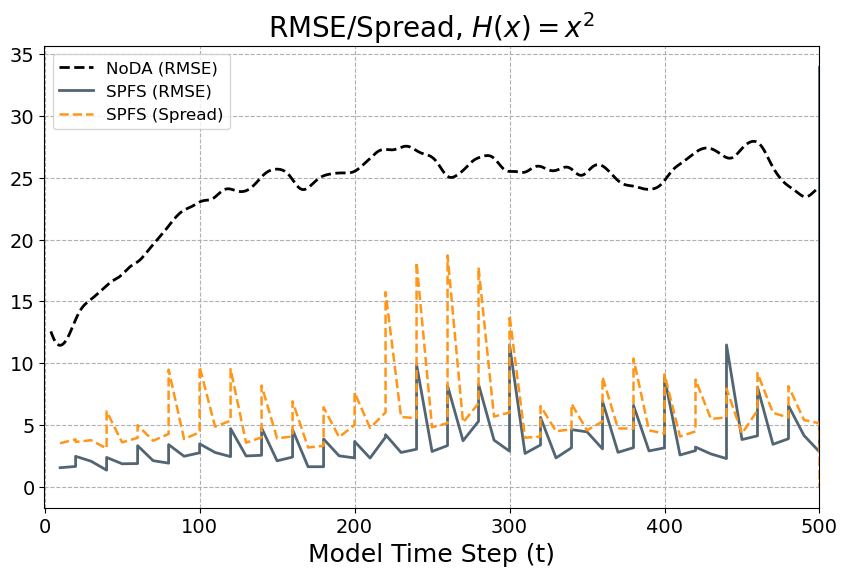

In [84]:
Output_list = [f'{Assim_method}']

adjust_factor = np.sqrt((ensemble_size+1)/ensemble_size)

if obs_type == 'linear':
    x_t_obs_space = x_t[::4, ens_start_time::assim_period]
    x_t_obs_space_full = x_t[::4, ens_start_time::]
    x_PFF_NoDA_obs_space = x_PFF_NoDA[::4, :, :]
elif obs_type == 'square':
    x_t_obs_space = np.square(x_t[::4, ens_start_time::assim_period])
    x_t_obs_space_full = np.square(x_t[::4, ens_start_time::])
    x_PFF_NoDA_obs_space = np.square(x_PFF_NoDA[::4, :, :])

# Exponential operator
# x_t_obs_space = np.exp(x_t[::4, ens_start_time::assim_period]/6)
# x_t_obs_space_full = np.exp(x_t[::4, ens_start_time::]/6)
# x_PFF_NoDA_obs_space = np.exp(x_PFF_NoDA[::4, :, :]/6)

x_PFF_NoDA_ens_mean = np.mean(x_PFF_NoDA_obs_space, axis=1)
rmse_NoDA = np.sqrt(np.mean((x_PFF_NoDA_ens_mean[:,4:integration_time_step] - x_t_obs_space_full[:,4:integration_time_step])**2, axis=0))
spread_NoDA = adjust_factor*np.sqrt(np.mean(np.var(x_PFF_NoDA_obs_space[:, :, 4:integration_time_step], axis=1, ddof=1), axis=0))

t_NoDA = np.arange(4, integration_time_step)
t = np.arange(1, Number_of_obs_sets)
tt = assim_period*np.repeat(t, 2)

plt.figure(figsize=(10, 6))
plt.plot(t_NoDA,spread_NoDA, label='NoDA (RMSE)', linewidth=2, color='k', linestyle='--')

for i in range(len(Output_list)):

    if obs_type == 'linear':
        prior_ens_obs_space = prior_ens_PFF[::4, :, :]
        posterior_ens_obs_space = posterior_ens_PFF[::4, :, :]
    elif obs_type == 'square':
        prior_ens_obs_space = np.square(prior_ens_PFF[::4, :, :])
        posterior_ens_obs_space = np.square(posterior_ens_PFF[::4, :, :])

    # Exponential operator
    # prior_ens_obs_space = np.exp(prior_ens_PFF[::4, :, :]/6)
    # posterior_ens_obs_space = np.exp(posterior_ens_PFF[::4, :, :]/6)

    prior_ens_mean = np.mean(prior_ens_obs_space, axis=1)
    posterior_ens_mean = np.mean(posterior_ens_obs_space, axis=1)

    rmse_prior = np.sqrt(np.mean((prior_ens_mean[:,1:Number_of_obs_sets] - x_t_obs_space[:,1:int(integration_time_step//assim_period)+1])**2, axis=0))
    rmse_posterior = np.sqrt(np.mean((posterior_ens_mean[:,1:Number_of_obs_sets] - x_t_obs_space[:,1:int(integration_time_step//assim_period)+1])**2, axis=0))

    spread_prior = adjust_factor*np.sqrt(np.mean(np.var(prior_ens_obs_space[:, :, 1:Number_of_obs_sets], axis=1, ddof=1), axis=0))
    spread_posterior = adjust_factor*np.sqrt(np.mean(np.var(posterior_ens_obs_space[:, :, 1:Number_of_obs_sets], axis=1, ddof=1), axis=0))

    rmse_timeseries = np.zeros(((Number_of_obs_sets-1)*2))
    rmse_timeseries[0:(int(integration_time_step//assim_period)*2):2] = rmse_prior
    rmse_timeseries[1:(int(integration_time_step//assim_period)*2):2] = rmse_posterior
    spread_timeseries = np.zeros(((Number_of_obs_sets-1)*2))
    spread_timeseries[0:(int(integration_time_step//assim_period)*2):2] = spread_prior
    spread_timeseries[1:(int(integration_time_step//assim_period)*2):2] = spread_posterior

    mask = ~(np.arange(len(rmse_timeseries)) % 4 == 0)
    rmse_timeseries = rmse_timeseries[mask]
    spread_timeseries = spread_timeseries[mask]
    # Adjust tt array as well
    tt1 = tt[mask]

    plt.plot(tt1,rmse_timeseries, label=f'{Output_list[i]} (RMSE)', linewidth=2, color='#526573')
    plt.plot(tt1,spread_timeseries, label=f'{Output_list[i]} (Spread)', linewidth=1.8, linestyle='--', color='#ff9618')

    print(np.mean(spread_prior[20::]), f'(Avg. Spread of {Output_list[i]} prior)')
    print(np.mean(rmse_prior[20::]), f'(Avg. RMSE of {Output_list[i]} prior)')
    print(np.mean(rmse_posterior[20::]), f'(Avg. RMSE of {Output_list[i]} posterior)')
    # print(np.mean(spread_prior[20::])-np.mean(rmse_prior[20::]), '(Difference)')

# plt.ylim(-0.3, 31)
plt.xlim(-0.1, 500)
plt.xlabel('Model Time Step (t)', fontsize=18)
if obs_type == 'linear':
    plt.title('RMSE/Spread, $H(x)=x$', fontsize=20)
elif obs_type == 'square':
    plt.title('RMSE/Spread, $H(x)=x^2$', fontsize=20)
legend = plt.legend(fontsize=12, loc='upper left')
plt.tick_params(labelsize=14)
plt.grid(True, linestyle='--')

plt.show()

#### 4.3 The kernel width used at each assimilation cycle

With the `fixed` option the kernel width stays at the base value $\alpha_0$. With the `adaptive` option it is narrowed by the factor $\rho$ whenever the prior ensemble straddles zero, which happens frequently for the nonlinear observation operator $H(\mathbf{x})=\mathbf{x}^2$. Each point is the width used by the SPFS update performed at the end of that assimilation window, diagnosed from the prior ensemble at the beginning of the window.

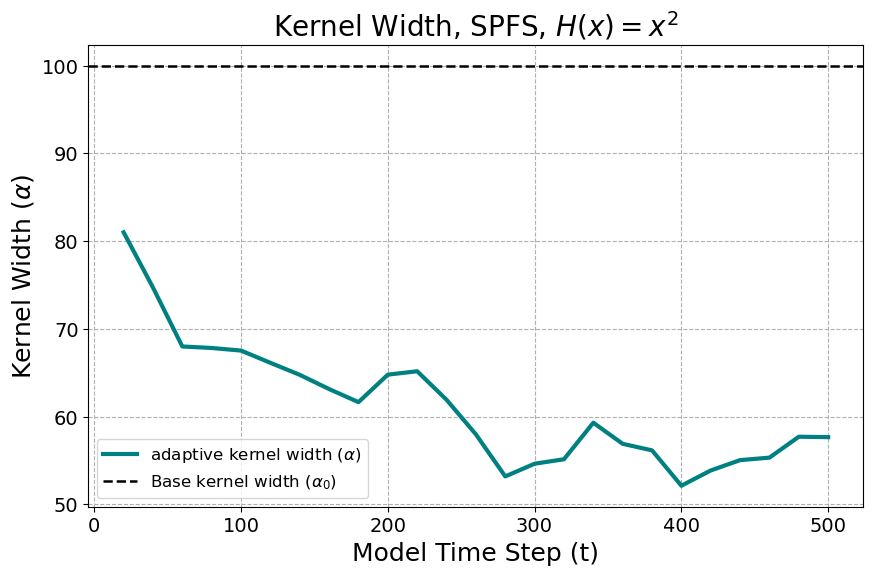

61.25406922539538 (Avg. kernel width over the assimilation cycles)


In [12]:
# Plot the kernel width versus the assimilation time
plt.figure(figsize=(10, 6))
t_assim = assim_window*np.arange(1, Number_of_smoother_cycles+1)
plt.plot(t_assim, alpha_list[1::], linewidth=3, color='#008080', label=f'{kernel_width_type} kernel width ' + r'($\alpha$)')
plt.axhline(alpha_0, color='k', linewidth=1.8, linestyle='--', label=r'Base kernel width ($\alpha_0$)')

if obs_type == 'linear':
    plt.title(f'Kernel Width, {Assim_method}, $H(x)=x$', fontsize=20)
elif obs_type == 'square':
    plt.title(f'Kernel Width, {Assim_method}, $H(x)=x^2$', fontsize=20)

plt.xlabel('Model Time Step (t)', fontsize=18)
plt.ylabel(r'Kernel Width ($\alpha$)', fontsize=18)
plt.legend(fontsize=12, loc='best')
plt.tick_params(labelsize=14)
plt.grid(True, linestyle='--')
plt.show()

print(np.mean(alpha_list[1::]), '(Avg. kernel width over the assimilation cycles)')